# 4. The sawtooth in the restriction rule
> Why one more sample can make a restriction decision less reliable

The DSS4NAFA dashboard restricts a unit when the share of its samples above the permissible level reaches the accepted proportion. This notebook follows one toy unit. A share `q` of the unit lies above the permissible level, so each random sample is above the level with probability `q`. The accepted proportion is 10%. The unit should be restricted when `q` is at least 10%. Part of a temporary series explaining the scoring work on the `scoring-experiments` branch: 0 a primer on Bayesian statistics, 1 campaigns, 2 MCDM, 3 scoring, 4 the sawtooth, 5 from `bayes` to `voi`, 6 spatial correlation and placement, 7 costs and a health limit. `_explain_overview.ipynb` summarises the design.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, beta, norm

In [ ]:
accepted = 0.1

## The count needed to restrict

With `n` samples, of which `k` are above the level, the unit is restricted when `k / n` is at least 0.1, that is when `k` is at least `0.1 n`. The share `k / n` can only move in steps of `1 / n`. With 10 samples, one exceedance gives exactly 10%, which is enough. With 11, it gives 9.1%, which is not. The count needed therefore jumps by one just after every multiple of 10:

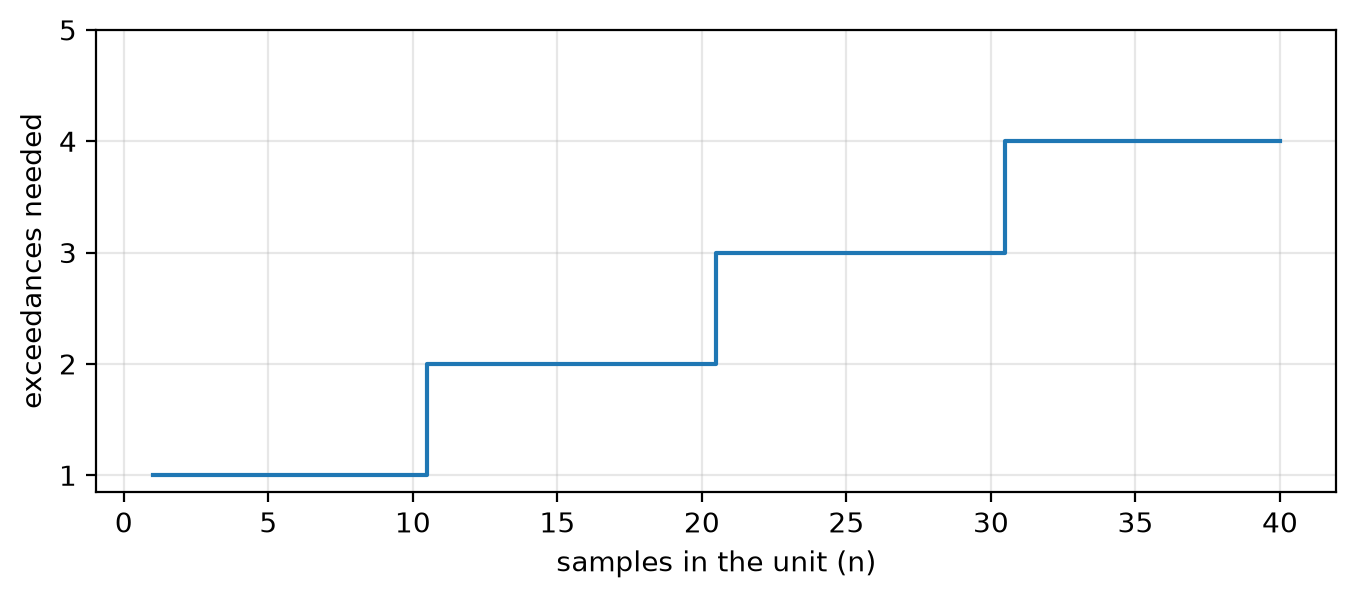

In [ ]:
def needed(n): return np.ceil(accepted * n - 1e-9).astype(int)

n = np.arange(1, 41)
fig, ax = plt.subplots(figsize=(8, 3))
ax.step(n, needed(n), where='mid')
ax.set(xlabel='samples in the unit (n)', ylabel='exceedances needed', yticks=[1, 2, 3, 4, 5])
ax.grid(alpha=0.3);

## One unit, one sample at a time

Draw 40 samples, one at a time, from a unit with `q = 0.12`, which should be restricted. After each sample, compare the exceedances so far with the count needed. The decision is right where the blue line reaches the orange one. This unit is restricted from its 4th sample. It drops out of restriction at its 11th, 21st and 31st sample, each time the orange line steps up, and is restricted again only after another exceedance:

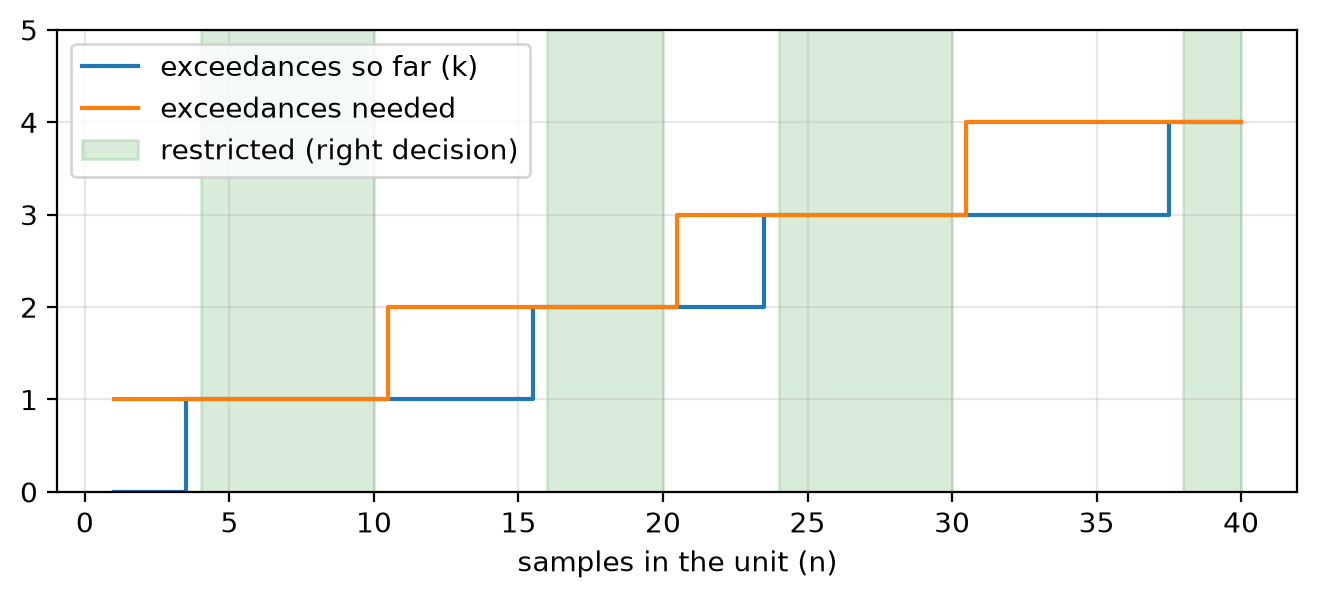

In [ ]:
rng = np.random.default_rng(18)
k = np.cumsum(rng.random(40) < 0.12)
fig, ax = plt.subplots(figsize=(8, 3))
ax.step(n, k, where='mid', label='exceedances so far (k)')
ax.step(n, needed(n), where='mid', label='exceedances needed')
ax.fill_between(n, 0, 5, where=k >= needed(n), step='mid', alpha=0.15, color='green', label='restricted (right decision)')
ax.set(xlabel='samples in the unit (n)', ylim=(0, 5))
ax.legend(loc='upper left'); ax.grid(alpha=0.3);

## The probability of a wrong decision

For a fixed `n`, the number of exceedances `k` follows a binomial distribution with parameters `n` and `q`. The probability of restricting is the probability that `k` reaches the count needed. Within a block of sample sizes, each extra sample is one more chance of an exceedance, so restricting gets more likely. At the start of the next block, it gets harder at once. The probability of a wrong decision follows a sawtooth, for a unit that should be restricted (`q = 0.12`, missed restriction) and for one that should not (`q = 0.08`, needless restriction):

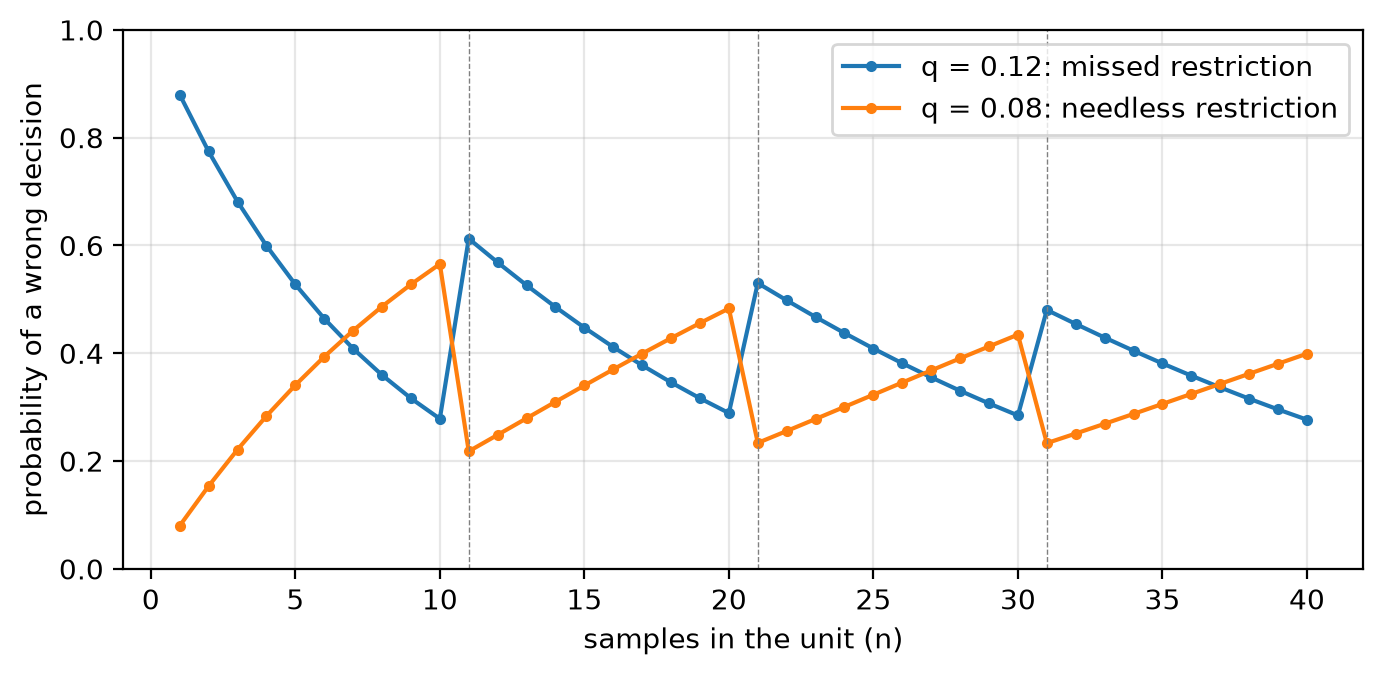

In [ ]:
def p_restrict(n, q): return binom.sf(needed(n) - 1, n, q)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n, 1 - p_restrict(n, 0.12), 'o-', ms=3, label='q = 0.12: missed restriction')
ax.plot(n, p_restrict(n, 0.08), 'o-', ms=3, label='q = 0.08: needless restriction')
for b in (11, 21, 31): ax.axvline(b, color='grey', lw=0.5, ls='--')
ax.set(xlabel='samples in the unit (n)', ylabel='probability of a wrong decision', ylim=(0, 1))
ax.legend(); ax.grid(alpha=0.3);

With 10 samples, the unit with `q = 0.12` is restricted when at least one sample is above the level: the decision is wrong 28% of the time. With 11 samples, it needs two: the decision is wrong 61% of the time. The 11th sample doubled the chance of a wrong decision:

In [ ]:
{n_: round(float(1 - p_restrict(np.array(n_), 0.12)), 2) for n_ in (10, 11)}

{10: 0.28, 11: 0.61}

A simulation of 100,000 units gives nearly the same numbers:

In [ ]:
rng = np.random.default_rng(0)
{n_: round(float(((rng.random((100_000, n_)) < 0.12).sum(1) < needed(np.array(n_))).mean()), 2) for n_ in (10, 11)}

{10: 0.28, 11: 0.62}

The teeth shrink as `n` grows, but slowly. A real campaign has 1 to 15 samples per unit, where the teeth dominate. Up to 10 samples the rule is very precautionary, because a single high value restricts the unit. From 11 samples it is much less so.

## A rule on the posterior probability

A rule that accounts for uncertainty restricts when the posterior probability that the share exceeds 10% is above a chosen level, here 50%, with a Beta(0.5 + k, 0.5 + n - k) posterior. It still decides on the count `k`, so it still needs a whole number of exceedances, and that number still steps up. The jumps move but do not disappear. With one sample, the posterior with no exceedance is so wide that the rule restricts anyway:

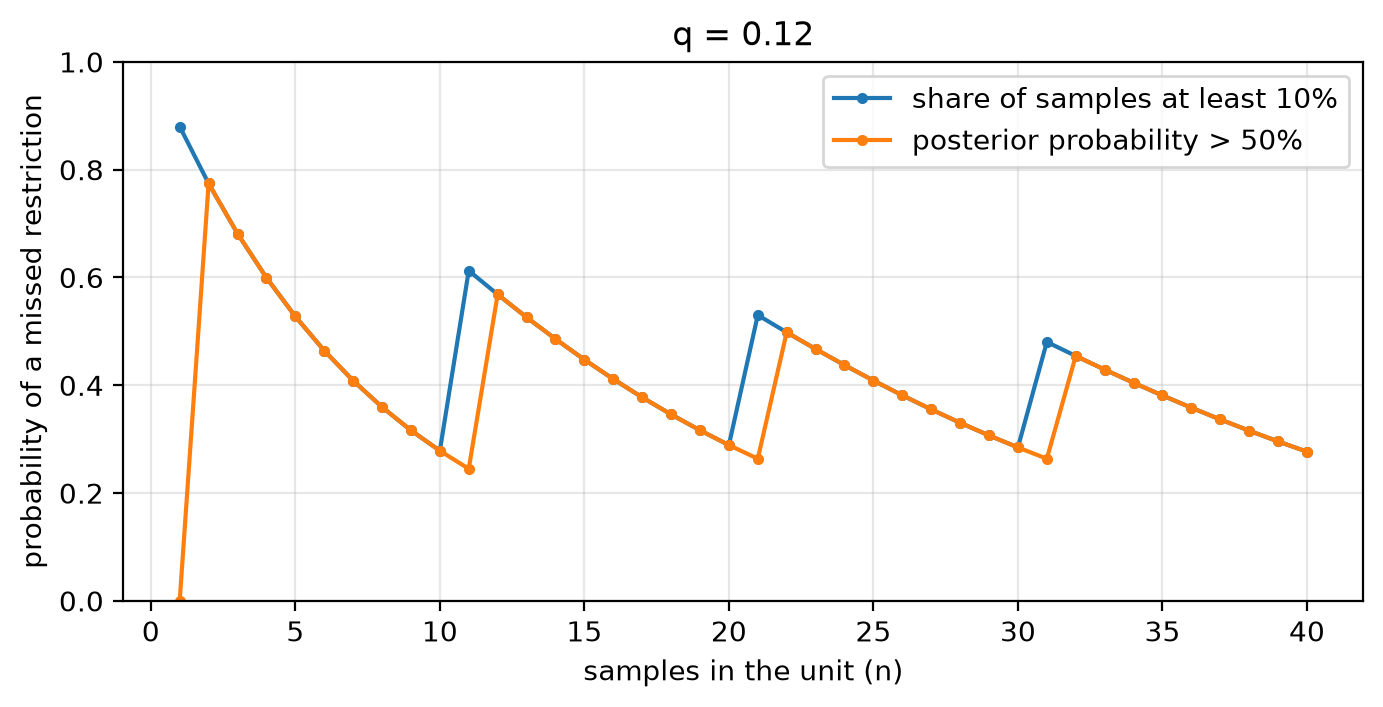

In [ ]:
def p_restrict_post(n_, q, level=0.5):
    k_ = np.arange(n_ + 1)
    return binom.pmf(k_, n_, q)[beta.sf(accepted, 0.5 + k_, 0.5 + n_ - k_) > level].sum()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n, 1 - p_restrict(n, 0.12), 'o-', ms=3, label='share of samples at least 10%')
ax.plot(n, [1 - p_restrict_post(n_, 0.12) for n_ in n], 'o-', ms=3, label='posterior probability > 50%')
ax.set(xlabel='samples in the unit (n)', ylabel='probability of a missed restriction', ylim=(0, 1), title='q = 0.12')
ax.legend(); ax.grid(alpha=0.3);

## A rule on the measured values

The sawtooth comes from deciding on a count. A rule that uses the measured values themselves, not only whether each is above the level, has a continuous statistic. Here the values are lognormal and 12% of the unit lies above the level. The rule fits a lognormal to the samples, estimates the share above the level from the fit, and restricts when it reaches 10%. Its probability of a wrong decision falls steadily with `n`. It is not lower on average than the count rule: deciding close to 10% is hard with any rule. It also depends on the distribution assumed, and is only as good as that assumption:

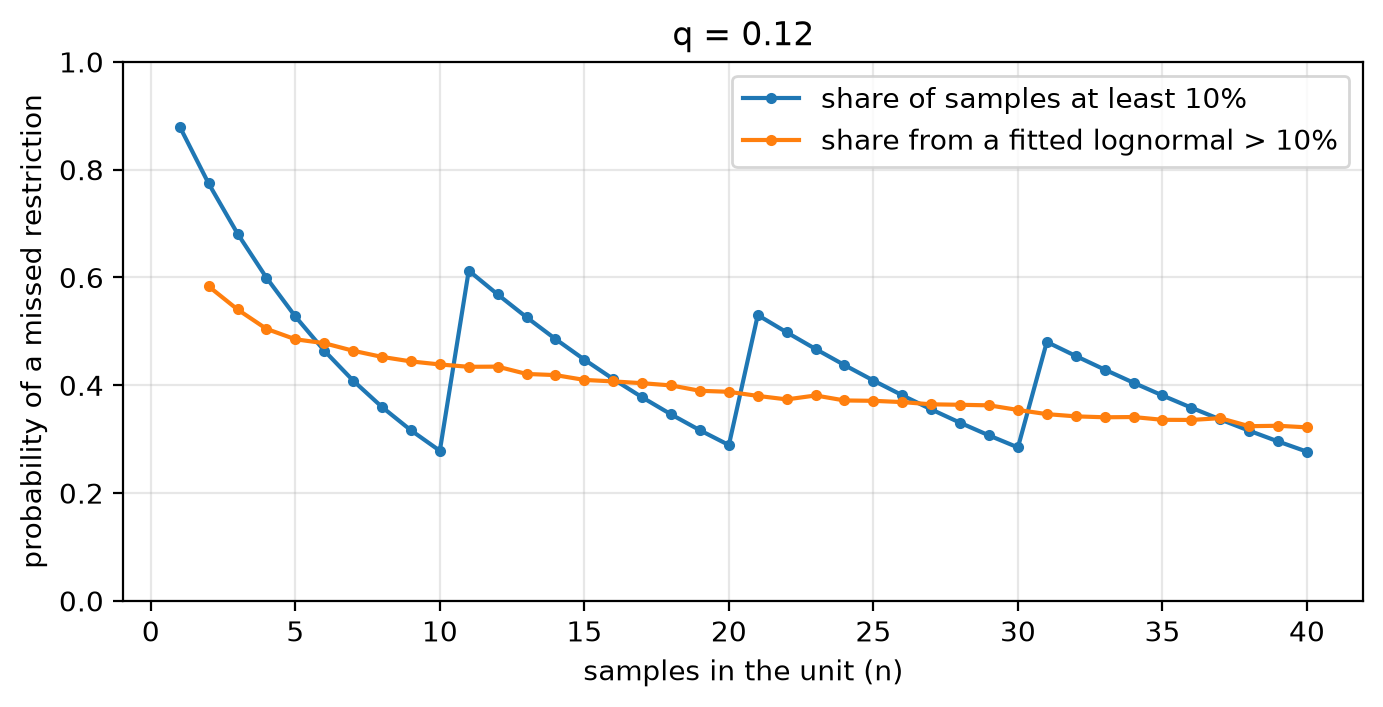

In [ ]:
q = 0.12
level = np.exp(norm.ppf(1 - q))
rng = np.random.default_rng(0)

def p_missed_fit(n_, reps=20_000):
    x = rng.normal(size=(reps, n_))
    share = norm.sf((np.log(level) - x.mean(1)) / x.std(1, ddof=1))
    return (share < accepted).mean()

n2 = np.arange(2, 41)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n, 1 - p_restrict(n, q), 'o-', ms=3, label='share of samples at least 10%')
ax.plot(n2, [p_missed_fit(n_) for n_ in n2], 'o-', ms=3, label='share from a fitted lognormal > 10%')
ax.set(xlabel='samples in the unit (n)', ylabel='probability of a missed restriction', ylim=(0, 1), title='q = 0.12')
ax.legend(); ax.grid(alpha=0.3);

## Summary

- Deciding on the share of samples above a level makes the count of exceedances needed jump at sample sizes set by the accepted proportion: 11, 21, 31 with 10%.
- After a jump, a unit that should be restricted is suddenly less likely to be. One more sample can double the chance of a wrong decision.
- Any rule that decides on the count of exceedances has jumps. A posterior rule moves them.
- A rule on the measured values, through a fitted distribution, has no jumps, at the cost of assuming a distribution.
- With the current rule, stopping at 10 samples can be better than taking an 11th.